In [1]:
import os
import sys
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torchvision.transforms import v2

os.chdir('/users/pbernius/melanoma_cnn')

from net_class import Net
from tunable_net import TunableNet


In [2]:
print(torch.__version__)

2.5.1+cu124


In [3]:
import inspect

import sys
import importlib

# 1. Forcefully evict 'net_class' from Python's hidden module system memory
if 'net_class' in sys.modules:
    del sys.modules['net_class']

# 2. Re-import completely fresh from the physical file path
import net_class
from net_class import Net
from tunable_net import TunableNet

print("Memory cache completely cleared and module reloaded!")

#print(TunableNet())


Memory cache completely cleared and module reloaded!


In [4]:
!nvidia-smi
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Fri Nov 13 10:48:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.71.05              Driver Version: 595.71.05      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Quadro RTX 6000                Off |   00000000:86:00.0 Off |                    0 |
| N/A   19C    P8             12W /  250W |       3MiB /  23040MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
img_size = 200

In [6]:
data = np.load(f"melanoma_training_data_{img_size}.npy", allow_pickle=True)
cutoff = int(0.8 * len(data))

training_data = data[:cutoff]
val_data = data[cutoff:]


In [7]:

# stack images into one tensor (N, H, W, 3), reorder to PyTorch's (N, 3, H, W), then copy into contiguous memory
train_x = torch.Tensor(np.array([item[0] for item in training_data])).permute(0, 3, 1, 2).contiguous()
#normalize data
#train_x = train_x/255


#one-hot vector labels tensor
train_y = torch.Tensor([item[1] for item in training_data])



# stack images into one tensor (N, H, W, 3), reorder to PyTorch's (N, 3, H, W), then copy into contiguous memory
val_x = torch.Tensor(np.array([item[0] for item in val_data])).permute(0, 3, 1, 2).contiguous()
#normalize data
#val_x = val_x/255


#one-hot vector labels tensor
val_y = torch.Tensor([item[1] for item in val_data])

/tmp/ipykernel_124/1793336850.py:8: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:278.)
  train_y = torch.Tensor([item[1] for item in training_data])


In [73]:
base_channels = 48
n_layers = 5
learning_rate = 0.0001
weight_decay = 0.005
channels = [base_channels * 2 ** min(i, 2) for i in range(n_layers)]


params = {
    "fc_units": 64,
    "num_pooling": 3,
    "dropout2d": 0.01,
    "dropout": 0.2,
    "kernel_size": 3,
    "adaptivepool": 10,
}



# call our cnn
net = TunableNet(channels, **params)
#for colab
net = net.to(device)

# set optimizer
optimizer = optim.AdamW(net.parameters(), lr=learning_rate, weight_decay=weight_decay)



# loss function
class_weights = torch.tensor([1.0, 3.0]).to(device)
train_loss_function = nn.CrossEntropyLoss(label_smoothing=0, weight=class_weights)
val_loss_function = nn.CrossEntropyLoss(label_smoothing=0)

#batch size
batch_size = 64

#number of epochs
epochs = 140


lr_sched = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)


In [74]:
#data augmentation
training_augmentation = v2.Compose([
        v2.RandomHorizontalFlip(p=0.5),
        v2.RandomVerticalFlip(p=0.5),
        v2.ColorJitter(brightness=0.065, contrast=0.13, saturation=0.07, hue=0.01),
        v2.RandomResizedCrop(size=img_size, scale=(0.95, 1.0))
    ])

Running epoch 1
Epoch 1: training loss 0.5936
Epoch 1: val loss 0.3348, AUC Score: 0.9556
Learning Rate: 0.0001
Running epoch 2
Epoch 2: training loss 0.4874
Epoch 2: val loss 0.2922, AUC Score: 0.9679
Learning Rate: 0.0001
Running epoch 3
Epoch 3: training loss 0.4393
Epoch 3: val loss 0.2560, AUC Score: 0.9716
Learning Rate: 0.0001
Running epoch 4
Epoch 4: training loss 0.4095
Epoch 4: val loss 0.2373, AUC Score: 0.9724
Learning Rate: 0.0001
Running epoch 5
Epoch 5: training loss 0.4003
Epoch 5: val loss 0.2546, AUC Score: 0.9736
Learning Rate: 0.0001
Running epoch 6
Epoch 6: training loss 0.3910
Epoch 6: val loss 0.2375, AUC Score: 0.9758
Learning Rate: 0.0001
Running epoch 7
Epoch 7: training loss 0.3855
Epoch 7: val loss 0.2460, AUC Score: 0.9778
Learning Rate: 0.0001
Running epoch 8
Epoch 8: training loss 0.3736
Epoch 8: val loss 0.2415, AUC Score: 0.9793
Learning Rate: 0.0001
Running epoch 9
Epoch 9: training loss 0.3680
Epoch 9: val loss 0.2259, AUC Score: 0.9799
Learning Rate:

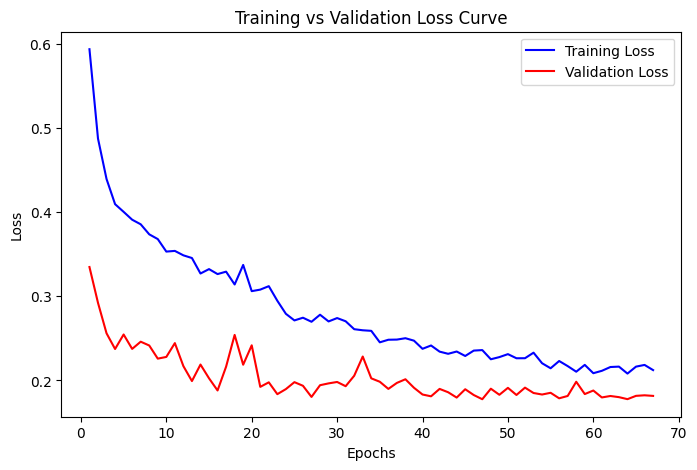

In [75]:
import copy
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt


patience = 20

best_val_loss = np.inf
best_val_auc = 0.0
best_weights = None
epochs_without_improvement = 0

train_losses = []
val_losses = []

for epoch in range(epochs):

    #data shuffler
    perm = torch.randperm(len(train_x))
    

    print(f"Running epoch {epoch+1}")
    net.train()

    train_loss = 0.0
    total_samples = 0

    
    for i in range(0, len(training_data), batch_size):

        #index for shuffling data
        idx = perm[i: i+batch_size]


        #print(f"EPOCH {epoch+1}, fraction complete: {i/len(train_x)}")

        batch_x = train_x[idx].float() / 255
        batch_y = train_y[idx]

        #for colab gpu
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        #resetting model parameters to zero each pass
        optimizer.zero_grad()

        augmented_image = torch.stack([training_augmentation(img) for img in batch_x])
 
        #pass batch of images to model
        outputs = net(augmented_image)

        #compute errors
        loss = train_loss_function(outputs, batch_y)
        n = len(batch_x)

        train_loss += loss.item() * n
        total_samples += n
        #print(f"Loss : {loss}")
        

        #backpropagation to calculate gradient of of loss with respect to model parameters
        loss.backward()


        #update model parameters based on previously computed gradient
        optimizer.step()


    train_loss = train_loss / total_samples
    train_losses.append(train_loss)

    print(f"Epoch {epoch+1}: training loss {train_loss:.4f}") 

    net.eval()
    val_loss = 0.0
    val_samples = 0
    val_scores = []
    val_labels = []

    with torch.no_grad():

        for j in range(0, len(val_data), batch_size):

            val_batch_x = val_x[j: j+batch_size].float() / 255
            val_batch_y = val_y[j: j+batch_size]

            #for colab gpu
            val_batch_x = val_batch_x.to(device)
            val_batch_y = val_batch_y.to(device)
    
    
            #pass batch of images to model
            outputs = net(val_batch_x)
    
            #compute errors
            n = len(val_batch_x)
            val_loss += val_loss_function(outputs, val_batch_y).item() * n
            val_samples += n

            
            probs = torch.softmax(outputs, dim=1)[:, 1]
            labels = val_batch_y[:, 1]

            val_scores.append(probs)
            val_labels.append(labels)

    val_loss = val_loss / val_samples
    val_losses.append(val_loss)

    lr_sched.step(val_loss)

    val_scores = torch.cat(val_scores).cpu().numpy()
    val_labels = torch.cat(val_labels).cpu().numpy()

    val_auc = roc_auc_score(val_labels, val_scores)

    print(f"Epoch {epoch+1}: val loss {val_loss:.4f}, AUC Score: {val_auc:.4f}")
    
    print(f"Learning Rate: {optimizer.param_groups[0]['lr']}")



    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(net.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement +=1
        if epochs_without_improvement >= patience:
            print(f"Stopping early at Epoch: {epoch+1}")
            break



# --- PLOTTING ---
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_losses) + 1), train_losses, label='Training Loss', color='blue')
plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss', color='red')
plt.title('Training vs Validation Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()



net.load_state_dict(best_weights)
torch.save(net.state_dict(), "saved_model.pth")


In [76]:
net = TunableNet(channels, **params)
#load in saved trained model
net.load_state_dict(torch.load('saved_model.pth', map_location=torch.device('cpu')))

#let pytorch know we are no longer training
net.eval()

#define image size
img_size = 200


#load in testing data
testing_data = np.load(f"melanoma_testing_data_{img_size}.npy", allow_pickle=True)



# stack images into one tensor (N, H, W, 3), reorder to PyTorch's (N, 3, H, W), then copy into contiguous memory
test_x = torch.Tensor(np.array([item[0] for item in testing_data])).permute(0, 3, 1, 2).contiguous()
#normalize data
test_x = test_x/255


#one-hot vector labels tensor
test_y = torch.Tensor([item[1] for item in testing_data])

/tmp/ipykernel_124/74527062.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load('saved_model.pth', map_location=torch.device('cpu')))


In [77]:
print(net)

TunableNet(
  (convolutional_layers): ModuleList(
    (0): Conv2d(3, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): Conv2d(48, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): Conv2d(96, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3-4): 2 x Conv2d(192, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (norm_layers): ModuleList(
    (0): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2-4): 3 x BatchNorm2d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (pooling_layers): ModuleList(
    (0-2): 3 x MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3-4): 2 x Identity()
  )
  (dropout_layers): ModuleList(
    (0-4): 5 x Dropout2d(p=0.01, inplace=False)
  )
  (adaptive_pool): AdaptiveAvgPool2d(output_size=10)
  (flatten): Flatten(start_dim=1, end_dim=

Accuracy: 0.917, AUC: 0.9755959999999999
TN 461, FP 39, FN 44, TP 456
Malignant recall: 0.9120, false-positive rate: 0.0780


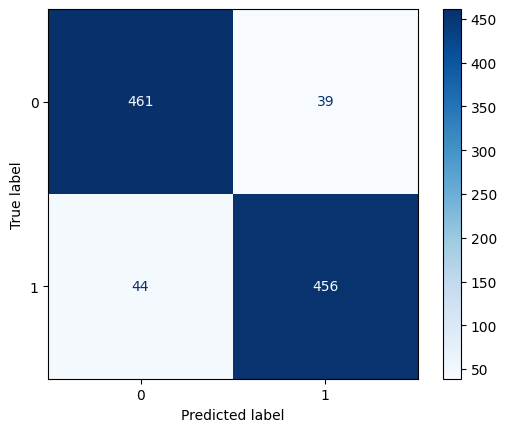

In [78]:
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
import matplotlib.pyplot as plt


correct = 0
total = 0

test_scores = []
test_preds = []

#ensure gradients are not calculated
with torch.no_grad():

    for i in range(len(test_x)):
        outputs = net(test_x[i:i+1])
        output = outputs[0]

        if output[0] >= output[1]:
            guess = "B"
        else:
            guess = "M"

        real_label = test_y[i]


        if real_label[0] >= real_label[1]:
            real_class = "B"
        else:
            real_class = "M"


        if guess == real_class:
            correct += 1

        total += 1




        probs = torch.softmax(outputs, dim=1)[:, 1]
        preds = torch.max(outputs, dim=1)
        test_scores.append(probs)
        test_preds.append(preds[1])

test_scores = torch.cat(test_scores).numpy()
test_auc = roc_auc_score(test_y[:, 1], test_scores)
cm = confusion_matrix(test_y[:, 1].numpy(), test_preds)


print(f"Accuracy: {round(correct/total, 4)}, AUC: {test_auc}")
tn, fp, fn, tp = cm.ravel()
print(f"TN {tn}, FP {fp}, FN {fn}, TP {tp}")
print(f"Malignant recall: {tp/(tp+fn):.4f}, false-positive rate: {fp/(fp+tn):.4f}")

matrix = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])
matrix.plot(cmap=plt.cm.Blues)


TN 464, FP 36, FN 45, TP 455
Malignant recall: 0.9100, false-positive rate: 0.0720
